# FrugalGPT — 3-Provider LLM Cascade on HEADLINES (small subset)

Cascade: **Textsynth `GPT-J` → AI21 `J1-Large` → OpenAI `GPT-4`** — three different providers,
trained fresh (not loaded from the paper's pretrained strategy, which only used OpenAI+Textsynth).

All three services have full cached coverage in `db/HEADLINES.sqlite` (verified: ~10,001 entries each),
so this runs with **no real API keys**. Everything else in the original 12-API set (Cohere, Anthropic,
AI21's other tiers) is only spot-cached — avoid those unless you have live keys.

## 1. Clone and install

In [1]:
!git clone -q https://github.com/stanford-futuredata/FrugalGPT
%cd FrugalGPT
!pip install -q .
# setup.py doesn't list google-generativeai, but modelservice.py imports+configures it
# at MODULE LEVEL, so importing FrugalGPT breaks without this installed.
# Patch scoring.py for transformers 5.x compatibility (repo targets an older transformers API)
path = "src/FrugalGPT/scoring.py"
with open(path) as f:
    lines = f.readlines()

lines = [l for l in lines if "logging_dir=" not in l]       # arg removed in transformers 5.x
content = "".join(lines).replace("evaluation_strategy=", "eval_strategy=")  # arg renamed

with open(path, "w") as f:
    f.write(content)

!pip install -q .   # reinstall with the patched source
print("patched and reinstalled")
!pip install -q google-generativeai

fatal: destination path 'FrugalGPT' already exists and is not an empty directory.
/content/FrugalGPT
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
patched and reinstalled


## 2. Download the response cache (skip the strategy zip — we're training fresh)

In [2]:
import os
os.makedirs("db", exist_ok=True)
if not os.path.exists("db/HEADLINES.sqlite"):
    !wget -q -P db/ https://github.com/lchen001/DataHolder/releases/download/v0.0.1/HEADLINES.sqlite
if not os.path.exists("db/qa_cache.sqlite"):
    !wget -q -P db/ https://github.com/lchen001/DataHolder/releases/download/v0.0.1/qa_cache.sqlite
print("HEADLINES.sqlite ready:", os.path.exists("db/HEADLINES.sqlite"))

HEADLINES.sqlite ready: True


## 3. Placeholder keys (dummy strings — required for import, not for cached calls)

In [3]:
os.environ['OPENAI_API_KEY'] = 'OPENAI_API_KEY'
os.environ['AI21_STUDIO_API_KEY'] = 'AI21_STUDIO_API_KEY'
os.environ['COHERE_STUDIO_API_KEY'] = 'COHERE_STUDIO_API_KEY'
os.environ['TEXTSYNTH_API_SECRET_KEY'] = 'TEXTSYNTH_API_SECRET_KEY'
os.environ['ANTHROPIC_API_KEY'] = 'ANTHROPIC_API_KEY'
os.environ['GEMINI_API_KEY'] = 'GEMINI_API_KEY'
os.environ['TOGETHER_API_KEY'] = 'TOGETHER_API_KEY'

## 4. Load training data

In [4]:
import sys, copy
sys.path.append("src/")
import FrugalGPT

N_TRAIN = 2000  # start small and cache-safe; raise toward 10000 if time/compute allow

train_raw = FrugalGPT.loadcsvdata("data/HEADLINES/train.csv")[:N_TRAIN]
prefix = open('config/prompt/HEADLINES/prefix_e8.txt').read()
train_data = FrugalGPT.formatdata(train_raw, prefix)
print("training on", len(train_data), "queries")

/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)
/content/FrugalGPT/src/FrugalGPT/scoring.py:79: SyntaxWarning: invalid escape sequence '\('
  a1 = re.findall('\([a-zA-Z]\)', text)
/content/FrugalGPT/src/FrugalGPT/scoring.py:84: SyntaxWarning: invalid escape sequence '\('
  return re.findall('\([a-zA-Z]\)', text)[-1]


training on 2000 queries


## 5. Train the 3-provider cascade

`LLMCascade()` defaults to `db_path='db/HEADLINES.sqlite'` internally — the populated cache —
so this step should hit cache for all three services and not need live keys.
This is the slow step (fine-tunes a small DistilBERT scorer per stage); expect several minutes.

In [6]:
import os
os.makedirs("strategy", exist_ok=True)

In [7]:
service_names = ['textsynth/gptj_6B', 'ai21/j1-large', 'openaichat/gpt-4']  # 3 providers

MyCascade = FrugalGPT.LLMCascade()
genparams = FrugalGPT.GenerationParameter(max_tokens=50, temperature=0.1, stop=['\n'])

BUDGET = 0.001  # $ per query, ~$10-20 total depending on N_EVAL below — tune this
MyCascade.train(
    trainingdata=train_data,
    budget=BUDGET,
    cascade_depth=3,
    service_names=service_names,
    genparams=genparams,
    prefix=prefix,
)
print("Training complete.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.447034,0.553243,0.776860
2,0.380887,0.469788,0.799816
3,0.592938,0.326694,0.880624
4,0.269234,0.330825,0.895317
5,0.346615,0.592487,0.875115
6,0.133693,0.522831,0.890725
7,0.005312,0.761405,0.853076
8,0.044592,0.639282,0.879706


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CRITICAL:root:construct data for ('textsynth/gptj_6B', 'ai21/j1-large', 'openaichat/gpt-4')
CRITICAL:root:the obj is -1754.0 and the var is [0.1526511  0.84482482]
CRITICAL:root:construct data for ('textsynth/gptj_6B', 'openaichat/gpt-4', 'ai21/j1-large')
CRITICAL:root:the obj is -1746.0 and the var is [0.12821256 0.12821256]
CRITICAL:root:construct data for ('ai21/j1-large', 'textsynth/gptj_6B', 'openaichat/gpt-4')
CRITICAL:root:the obj is -1724.0 and the var is [0.23654398 0.39423313]
CRITICAL:root:construct data for ('ai21/j1-large', 'openaichat/gpt-4', 'textsynth/gptj_6B')
CRITICAL:root:the obj is -1604.0 and the var is [0.07693154 0.07693154]
CRITICAL:root:construct data for ('openaichat/gpt-4', 'textsynth/gptj_6B', 'ai21/j1-large')
CRITICAL:root:Base API too expensive, skip
CRITICAL:root:construct data for ('openaichat/gpt-4', 'ai21/j1-large', 'textsynth/gptj_6B')
CRITICAL:root:Base API too expensive, skip


Training complete.


## 6. Evaluate: cascade vs. GPT-4 alone

In [8]:
N_EVAL = 500  # bump toward 10000 once the small run looks right

test_raw = FrugalGPT.loadcsvdata("data/HEADLINES/test.csv")[:N_EVAL]
test_data = FrugalGPT.formatdata(test_raw, prefix)

result_cascade = MyCascade.get_completion_batch(queries=test_data, genparams=genparams)
score_cascade = FrugalGPT.compute_score(result_cascade)

# IMPORTANT FIX: LLMforAll() defaults to db_path='db/qa_cache.sqlite' (nearly empty!).
# Point it at the populated cache explicitly, or this will try live OpenAI calls.
MyLLMforAll = FrugalGPT.LLMforAll(db_path="db/HEADLINES.sqlite")
result_gpt4 = MyLLMforAll.get_completion_batch(queries=test_data, genparams=genparams, service_name='openaichat/gpt-4')
score_gpt4 = FrugalGPT.compute_score(result_gpt4)

print("FrugalGPT (3-provider cascade):", score_cascade)
print("GPT-4 alone:                   ", score_gpt4)

500it [00:00, 513.25it/s]

FrugalGPT (3-provider cascade): {'em': np.float64(0.854), 'cost': np.float64(0.0008241132)}
GPT-4 alone:                    {'em': np.float64(0.854), 'cost': np.float64(0.0066702)}


## 7. Summary table + chart

,Approach,Accuracy,Cost ($),Cost Savings
0,GPT-4 (alone),0.854,0.006780,0.00000
1,FrugalGPT (GPT-J → J1-Large → GPT-4),0.854,0.000056,0.99174


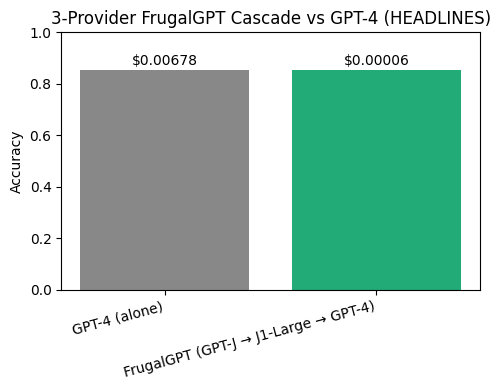

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

summary = pd.DataFrame({
    "Approach":  ["GPT-4 (alone)", "FrugalGPT (GPT-J \u2192 J1-Large \u2192 GPT-4)"],
    "Accuracy":  [score_gpt4['em'], score_cascade['em']],
    "Cost ($)":  [MyLLMforAll.get_cost(), MyCascade.get_cost()],
})
summary["Cost Savings"] = 1 - summary["Cost ($)"] / summary["Cost ($)"].iloc[0]
display(summary)

fig, ax = plt.subplots(figsize=(5,4))
ax.bar(summary["Approach"], summary["Accuracy"], color=["#888","#2a7"])
ax.set_ylabel("Accuracy")
ax.set_title("3-Provider FrugalGPT Cascade vs GPT-4 (HEADLINES)")
ax.set_ylim(0, 1)
for i, row in summary.iterrows():
    ax.text(i, row["Accuracy"] + 0.02, f'${row["Cost ($)"]:.5f}', ha="center")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()



- Cascade order: **Textsynth GPT-J (cheapest) → AI21 J1-Large (mid) → OpenAI GPT-4 (most expensive/reliable)** —
  three different API providers, chosen because they're the only 3rd-party services with full cached
  coverage on HEADLINES besides OpenAI's own two tiers.
- `N_TRAIN` / `N_EVAL` are kept small for resource constraints.
- If you ever see `---invoke new API call---` printed, that query missed the cache — a real key would be
  required for it. With this service combo you shouldn't see it.